# Projeto Final T4 - Manutenção Preditiva

**Autor acadêmico responsável:** Fabiano Rodrigo Costa. SCTEC/SENAI, Desenvolvimento de IA para Análise Preditiva, Turma T4.

Este notebook reúne as sete fases de exploração, preparação, modelagem e avaliação de falhas. A execução registrada contém 15 células de código sem exceções. Prazo de submissão **16/11/2026 às 22h, horário de Brasília**.

Execute todas as células em ordem, a partir da raiz, usando Python 3.12 e o kernel **T4 (.venv)**. As instruções de ambiente estão em `README.md`, e os requisitos detalhados em `docs/checklist-rubrica.md`.

O CSV oficial é lido por caminho relativo. A EDA descreve a base completa conforme a rubrica. As transformações de modelagem são ajustadas exclusivamente nos treinos das dobras, a partir de dados brutos. As escolhas de hiperparâmetros foram registradas antes da avaliação no teste.

## Fase 1: Análise Exploratória (EDA)

In [1]:
import time
import psutil
inicio_execucao_t4 = time.perf_counter()
processo_t4 = psutil.Process()
cpu_inicio_t4 = processo_t4.cpu_times()

In [2]:
%matplotlib inline
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

sns.set_theme(style='whitegrid')
SEMENTE = 42
CAMINHO_CSV = Path('data') / 'raw' / 'manutencao_preditiva.csv'
HASH_ORIGINAL = hashlib.sha256(CAMINHO_CSV.read_bytes()).hexdigest()
dados = pd.read_csv(CAMINHO_CSV)
ALVO = 'falha_maquina'
CONTINUAS = ['temperatura_ar_k', 'temperatura_processo_k',
             'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']
IDS = ['udi', 'id_produto']
CAUSAS = ['falha_twf', 'falha_hdf', 'falha_pwf', 'falha_osf', 'falha_rnf']
assert dados[ALVO].notna().all() and set(dados[ALVO].unique()) <= {0, 1}
print('Python do kernel:', sys.executable)
print(f'Dimensões: {dados.shape[0]} linhas e {dados.shape[1]} colunas')
display(dados.dtypes.rename('tipo').to_frame())
display(dados.describe())

Python do kernel: C:\Users\fabia\t4-manutencao-preditiva\.venv\Scripts\python.exe
Dimensões: 10000 linhas e 14 colunas


,tipo
udi,int64
id_produto,str
tipo,str
temperatura_ar_k,float64
temperatura_processo_k,float64
velocidade_rotacao_rpm,float64
torque_nm,float64
desgaste_ferramenta_min,int64
falha_maquina,int64
falha_twf,int64


,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Distribuição do alvo e gráficos
Contagens e percentuais são calculados na base oficial antes de qualquer transformação.
Os histogramas mostram as distribuições dos sensores; o gráfico de barras evidencia o desbalanceamento; o mapa de Pearson explora relações lineares entre sensores e alvo. IDs e causas históricas ficam fora do mapa para não sugerir sua utilização como atributos preditivos.

,contagem,percentual
falha_maquina,,
0,9661,96.61
1,339,3.39


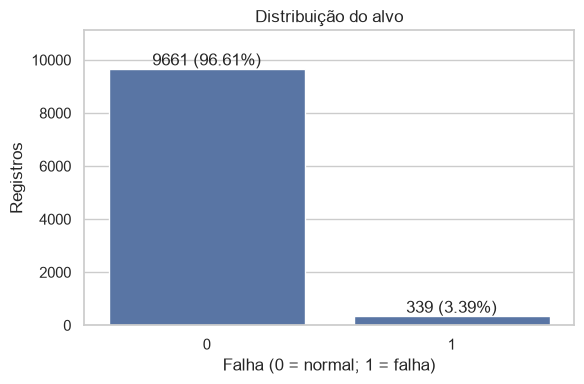

In [3]:
distribuicao_alvo = (dados[ALVO].value_counts().sort_index()
                     .rename_axis(ALVO).to_frame('contagem'))
distribuicao_alvo['percentual'] = distribuicao_alvo['contagem'] / len(dados) * 100
display(distribuicao_alvo)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=distribuicao_alvo.index.astype(str), y=distribuicao_alvo['contagem'], ax=ax)
for i, (_, linha) in enumerate(distribuicao_alvo.iterrows()):
    ax.text(i, linha['contagem'], f"{int(linha['contagem'])} ({linha['percentual']:.2f}%)", ha='center', va='bottom')
ax.set(xlabel='Falha (0 = normal; 1 = falha)', ylabel='Registros', title='Distribuição do alvo')
ax.set_ylim(0, distribuicao_alvo['contagem'].max() * 1.15)
plt.tight_layout(); plt.show()

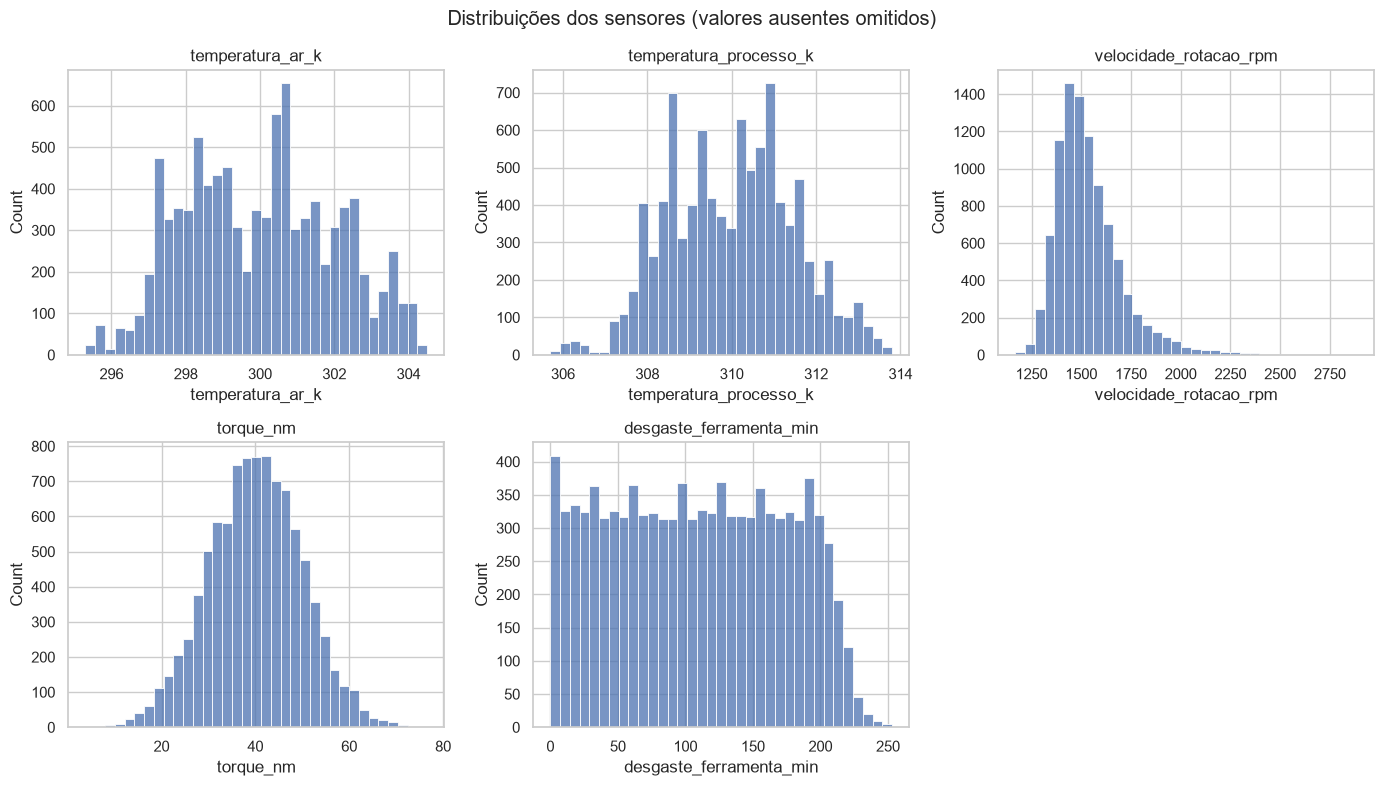

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for coluna, ax in zip(CONTINUAS, axes.flat):
    sns.histplot(data=dados, x=coluna, bins=35, ax=ax)
    ax.set_title(coluna)
axes.flat[-1].set_visible(False)
fig.suptitle('Distribuições dos sensores (valores ausentes omitidos)')
plt.tight_layout(); plt.show()

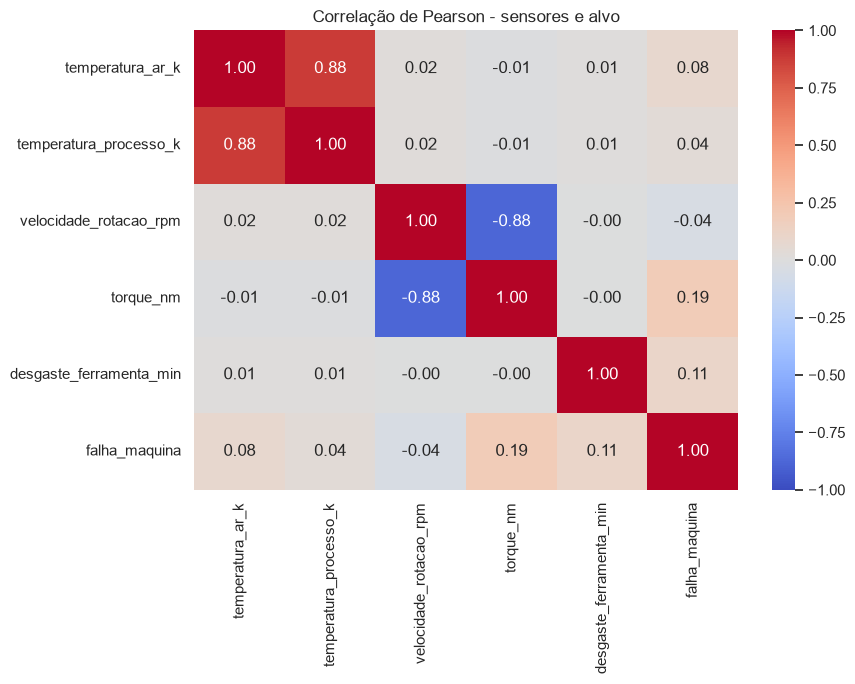

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(dados[CONTINUAS + [ALVO]].corr(method='pearson'),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlação de Pearson - sensores e alvo')
plt.tight_layout(); plt.show()

### Interpretação das saídas reais
A base tem **10,000 registros e 14 colunas**. Há **9661 registros normais (96.61%)** e **339 falhas (3.39%)**. Um classificador que sempre escolhesse a classe normal já alcançaria 96.61% de acurácia; portanto, acurácia isolada pode ocultar falhas não detectadas. A modelagem balanceou exclusivamente os treinos e avaliou recall, precisão, F1 e matrizes de confusão, mantendo a acurácia exigida.

A rotação tem mediana **1504.0 rpm**, média **1539.2 rpm** e máximo **2886.0 rpm**. Esses números e o histograma indicam uma cauda à direita. Pearson entre rotação e torque é **-0.875**; entre temperaturas do ar e processo, **0.877**. Essas associações motivam avaliar atributos físicos combinados, sem interpretar correlação como causalidade. As escalas dos sensores diferem e foram padronizadas no ramo numérico do KNN. A árvore mantém a escala original. A categoria `tipo` recebeu One-Hot Encoding, e os IDs foram excluídos dos preditores.

## Fase 2: Limpeza e Tratamento de Dados (Data Prep)

Diagnosticamos duplicatas completas, ausências e extremos sem alterar o arquivo. Duplicatas completas são removidas antes da divisão para impedir que uma cópia idêntica apareça em treino e teste. Não removemos registros apenas por repetirem medidas de sensores: podem representar observações legítimas distintas.

Boxplots e cercas de 1,5 IQR são diagnósticos exploratórios, não regras automáticas de exclusão. Extremos podem ser sinais úteis de falha. Não serão removidos nem truncados neste bloco. A imputação é ajustada depois da divisão. A Fase 4 registra a preparação inicial, e os pipelines da Fase 5 repetem esse ajuste dentro dos treinos de cada dobra.

Duplicatas completas: 0


,ausentes
udi,0
id_produto,0
tipo,0
temperatura_ar_k,500
temperatura_processo_k,500
velocidade_rotacao_rpm,500
torque_nm,500
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0


,limite_inferior,limite_superior,outliers_IQR,percentual_validos
temperatura_ar_k,293.50,306.30,0,0.000000
temperatura_processo_k,305.35,314.55,0,0.000000
velocidade_rotacao_rpm,1138.00,1898.00,398,4.189474
torque_nm,12.70,67.10,63,0.663158
desgaste_ferramenta_min,-110.50,325.50,0,0.000000


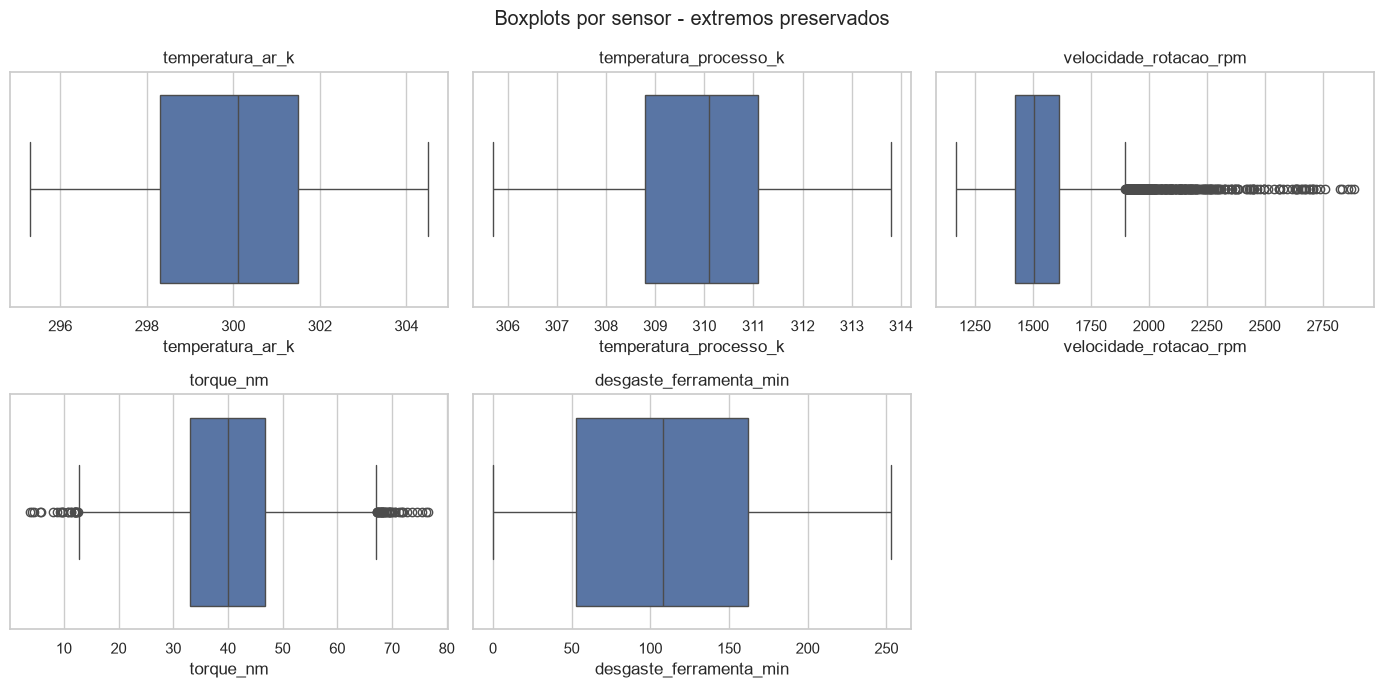

In [6]:
duplicadas = int(dados.duplicated().sum())
print('Duplicatas completas:', duplicadas)
display(dados.isna().sum().rename('ausentes').to_frame())
q1 = dados[CONTINUAS].quantile(0.25)
q3 = dados[CONTINUAS].quantile(0.75)
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mascara_outliers = ((dados[CONTINUAS] < limite_inferior) |
                   (dados[CONTINUAS] > limite_superior))
diagnostico_outliers = pd.DataFrame({
    'limite_inferior': limite_inferior, 'limite_superior': limite_superior,
    'outliers_IQR': mascara_outliers.sum(),
    'percentual_validos': mascara_outliers.sum() / dados[CONTINUAS].count() * 100})
display(diagnostico_outliers)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for coluna, ax in zip(CONTINUAS, axes.flat):
    sns.boxplot(data=dados, x=coluna, ax=ax)
    ax.set_title(coluna)
axes.flat[-1].set_visible(False)
fig.suptitle('Boxplots por sensor - extremos preservados')
plt.tight_layout(); plt.show()
dados_limpos = dados.drop_duplicates().copy()

### Diagnóstico e estratégia de imputação
Foram observadas **0 duplicatas completas** e **2000 células ausentes**: `temperatura_ar_k`: 500, `temperatura_processo_k`: 500, `velocidade_rotacao_rpm`: 500, `torque_nm`: 500.
Contagens de extremos por 1,5 IQR: `temperatura_ar_k`: 0, `temperatura_processo_k`: 0, `velocidade_rotacao_rpm`: 398, `torque_nm`: 63, `desgaste_ferramenta_min`: 0. Os sensores com maior cauda e extremos tornam a **mediana** uma escolha robusta previamente definida para as variáveis contínuas. A ausência de outliers em algum sensor não obriga usar média; uma política uniforme e robusta simplifica a reprodução. Os valores das medianas são estimados exclusivamente nos treinos das dobras, sem usar as estatísticas exploratórias globais para ajustar os transformadores. Mesmo as colunas sem nulos passam pelo mesmo transformador. `tipo` usa a moda aprendida somente no treino caso haja ausências; o alvo jamais será imputado.

## Fase 3: Feature Engineering

A função abaixo é chamada após a imputação. Criamos `potencia_mecanica_w = velocidade_rotacao_rpm * torque_nm * (2π/60)`, em watts: é o produto sugerido no enunciado com conversão de rpm para rad/s. Trata-se de uma estimativa baseada nos sensores, não de uma medição elétrica. A fórmula é fixa e não aprende parâmetros no teste. Validamos entradas e saída finitas; não criamos a coluna na base original.

In [7]:
def adicionar_potencia(quadro):
    resultado = quadro.copy()
    valores = resultado[CONTINUAS].to_numpy(dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError('Trate nulos e valores não finitos antes da variável derivada.')
    resultado['potencia_mecanica_w'] = (
        resultado['velocidade_rotacao_rpm'] * resultado['torque_nm'] * 2 * np.pi / 60)
    assert np.isfinite(resultado['potencia_mecanica_w']).all()
    return resultado

## Fase 4: Divisão e Balanceamento dos Dados

A divisão estratificada 80/20 usa semente 42. As variáveis preditoras incluem sensores e `tipo`, com exclusão dos IDs, do alvo e das cinco causas históricas. As causas descrevem a falha já ocorrida e produziriam vazamento se usadas como preditores.

A célula seguinte preserva a preparação validada no Bloco 01. Os objetos `X_treino` e `X_teste` documentam o tratamento inicial. Os classificadores usam `X_treino_bruto`, e seus pipelines reajustam imputação, engenharia, codificação, escala e balanceamento em cada treino de dobra.

O Random Under Sampling está implementado nos pipelines da Fase 5 e atua exclusivamente nos treinos. Teste e validação mantêm suas distribuições. A mensagem de pendências exibida ao final da preparação inicial registra o ponto anterior à execução desses pipelines, concluídos nas seções seguintes.

In [8]:
X = dados_limpos[CONTINUAS + ['tipo']].copy()
y = dados_limpos[ALVO].copy()
assert not set(IDS + CAUSAS + [ALVO]) & set(X.columns)
X_treino_bruto, X_teste_bruto, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
assert set(X_treino_bruto.index).isdisjoint(X_teste_bruto.index)
assert X_treino_bruto[CONTINUAS].notna().any().all(), 'Sensor sem observações no treino.'
assert X_treino_bruto['tipo'].notna().any(), 'Categoria sem observações no treino.'
imputador_numerico = SimpleImputer(strategy='median')
imputador_tipo = SimpleImputer(strategy='most_frequent')
imputador_numerico.fit(X_treino_bruto[CONTINUAS])
imputador_tipo.fit(X_treino_bruto[['tipo']].astype(object).where(X_treino_bruto[['tipo']].notna(), np.nan))

def preparar(quadro):
    numericos = pd.DataFrame(imputador_numerico.transform(quadro[CONTINUAS]),
                            columns=CONTINUAS, index=quadro.index)
    categorias = quadro[['tipo']].astype(object).where(quadro[['tipo']].notna(), np.nan)
    numericos['tipo'] = imputador_tipo.transform(categorias).ravel()
    return adicionar_potencia(numericos)

X_treino = preparar(X_treino_bruto)
X_teste = preparar(X_teste_bruto)
assert np.allclose(imputador_numerico.statistics_, X_treino_bruto[CONTINUAS].median())
assert not X_treino.isna().any().any() and not X_teste.isna().any().any()
assert X_treino.index.equals(y_treino.index) and X_teste.index.equals(y_teste.index)
assert not set(IDS + CAUSAS + [ALVO]) & set(X_treino.columns)
print('Treino:', X_treino.shape, '| Teste:', X_teste.shape)
display(pd.DataFrame({'mediana_ajustada_no_treino': imputador_numerico.statistics_}, index=CONTINUAS))
display(pd.concat([y_treino.value_counts().rename('treino'),
                   y_teste.value_counts().rename('teste')], axis=1).sort_index())
display(X_treino.head())
display(pd.concat([X_treino['potencia_mecanica_w'].describe().rename('treino'),
                   X_teste['potencia_mecanica_w'].describe().rename('teste')], axis=1))

Treino: (8000, 7) | Teste: (2000, 7)


,mediana_ajustada_no_treino
temperatura_ar_k,300.1
temperatura_processo_k,310.1
velocidade_rotacao_rpm,1503.5
torque_nm,40.1
desgaste_ferramenta_min,107.0


,treino,teste
falha_maquina,,
0,7729,1932
1,271,68


,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,tipo,potencia_mecanica_w
4058,300.1,310.1,1503.5,40.1,54.0,M,6313.590688
1221,297.0,308.3,1399.0,46.4,132.0,M,6797.736296
6895,301.0,311.6,1357.0,45.6,137.0,M,6479.974671
9863,298.9,309.8,1411.0,56.3,84.0,L,8318.864043
8711,297.1,308.5,1733.0,28.7,50.0,L,5208.456932


,treino,teste
count,8000.000000,2000.000000
mean,6283.495348,6266.064716
std,1046.370025,1024.976054
min,1148.440610,1715.833188
25%,5599.409812,5614.130792
50%,6313.590688,6313.590688
75%,6967.125736,6892.795654
max,10469.923005,10233.151638


In [9]:
assert hashlib.sha256(CAMINHO_CSV.read_bytes()).hexdigest() == HASH_ORIGINAL
print('CSV original preservado. SHA-256:', HASH_ORIGINAL)
print('Preparação concluída; balanceamento, codificação, escala e modelos pendentes.')

CSV original preservado. SHA-256: 21f0032f6a94bacc897cbc7a26de9ffdc3fcd68adbc087db267a2d36d2dfea74
Preparação concluída; balanceamento, codificação, escala e modelos pendentes.


### Continuação do Bloco 02

O diagnóstico e a preparação acima correspondem ao Bloco 01. A partir daqui, a modelagem usa `X_treino_bruto` para reajustar as transformações dentro de cada dobra de validação. Os objetos já imputados `X_treino` e `X_teste` continuam disponíveis como evidência da preparação anterior.

Random Under Sampling equaliza as classes por seleção aleatória de registros existentes, com semente 42. A escolha simplifica o tratamento de categorias e limita o custo computacional. A redução da classe majoritária descarta informação, que deve ser reconhecida na interpretação. O sampler é ajustado pelo pipeline em cada treino de dobra e no ajuste final. A validação e o teste mantêm a distribuição original.

## Fase 5: Escalonamento de Variáveis (StandardScaler)

O ramo numérico ajusta medianas, aplica a função física `adicionar_potencia` e, no KNN, ajusta o StandardScaler. São seis atributos numéricos após a engenharia. O ramo categórico ajusta a moda de `tipo` e One-Hot Encoding com `handle_unknown='ignore'`. A codificação não impõe uma distância ordinal entre L, M e H.

A Árvore de Decisão usa as mesmas imputações e engenharia, com valores numéricos sem escalonamento. Seus cortes dependem da ordenação dos atributos e dispensam padronização. O scaler fica no ramo numérico do KNN, preservando os indicadores binários de categoria.

A ordem é preparação, balanceamento e classificador. Os parâmetros de imputação e escala são aprendidos sobre todos os registros do treino de cada dobra antes da subamostragem. O teste recebe somente transformações já ajustadas. A etapa `fit_resample` é utilizada apenas em `fit`, por meio do pipeline de imbalanced-learn.

In [10]:
import copy
import json
import importlib.metadata as metadata
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.under_sampling import RandomUnderSampler
from IPython.display import JSON
from threadpoolctl import threadpool_limits

# Limita o trabalho numérico a uma thread durante este experimento.
limite_threads_t4 = threadpool_limits(limits=1)
COLUNAS_PERMITIDAS = CONTINUAS + ['tipo']
assert list(X_treino_bruto.columns) == COLUNAS_PERMITIDAS
assert list(X_teste_bruto.columns) == COLUNAS_PERMITIDAS
assert not set(IDS + CAUSAS + [ALVO]).intersection(COLUNAS_PERMITIDAS)
assert X_treino_bruto.index.equals(y_treino.index)
assert X_teste_bruto.index.equals(y_teste.index)
assert set(X_treino_bruto.index).isdisjoint(X_teste_bruto.index)
teste_preservado_X = X_teste_bruto.copy(deep=True)
teste_preservado_y = y_teste.copy(deep=True)


def construir_pipeline(modelo, escalonar):
    etapas_numericas = [
        ('imputacao', SimpleImputer(strategy='median').set_output(transform='pandas')),
        ('potencia', FunctionTransformer(adicionar_potencia, validate=False)),
    ]
    if escalonar:
        etapas_numericas.append(('escala', StandardScaler()))
    categorias = SklearnPipeline([
        ('imputacao', SimpleImputer(strategy='most_frequent')),
        ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    preparacao = ColumnTransformer([
        ('numericos', SklearnPipeline(etapas_numericas), CONTINUAS),
        ('categorias', categorias, ['tipo']),
    ], remainder='drop', sparse_threshold=0)
    return ImbalancedPipeline([
        ('preparacao', preparacao),
        ('balanceamento', RandomUnderSampler(random_state=SEMENTE)),
        ('modelo', modelo),
    ])


pipelines = {
    'KNN': construir_pipeline(KNeighborsClassifier(n_jobs=1), escalonar=True),
    'Arvore': construir_pipeline(DecisionTreeClassifier(random_state=SEMENTE), escalonar=False),
}
grade_parametros = {
    'KNN': {'modelo__n_neighbors': [3, 5, 7]},
    'Arvore': {'modelo__max_depth': [3, 5, None]},
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
dobras = list(cv.split(X_treino_bruto, y_treino))
print('Classes no treino original:', y_treino.value_counts().sort_index().to_dict())
print('Validação cruzada estratificada com três dobras e semente', SEMENTE)

Classes no treino original: {0: 7729, 1: 271}
Validação cruzada estratificada com três dobras e semente 42


### Verificação das dobras

Cada verificação ajusta um clone do pipeline somente nos índices de treino da dobra. Comparamos as medianas aprendidas com as medianas desse subconjunto e verificamos os registros selecionados pelo sampler. A transformação dos registros de validação preserva a quantidade e a ordem das amostras. As grades seguintes repetem esse procedimento por meio de GridSearchCV.

In [11]:
auditoria_dobras = []
for numero_dobra, (indices_ajuste, indices_validacao) in enumerate(dobras, start=1):
    X_ajuste = X_treino_bruto.iloc[indices_ajuste]
    y_ajuste = y_treino.iloc[indices_ajuste]
    X_validacao = X_treino_bruto.iloc[indices_validacao]
    assert X_ajuste.index.equals(y_ajuste.index)
    assert set(X_ajuste.index).isdisjoint(X_validacao.index)
    assert set(X_ajuste.index).isdisjoint(X_teste_bruto.index)
    for nome, pipeline in pipelines.items():
        ajuste_dobra = clone(pipeline).fit(X_ajuste, y_ajuste)
        preparacao_dobra = ajuste_dobra.named_steps['preparacao']
        numericos_dobra = preparacao_dobra.named_transformers_['numericos']
        assert np.allclose(numericos_dobra.named_steps['imputacao'].statistics_,
                           X_ajuste[CONTINUAS].median().to_numpy())
        if nome == 'KNN':
            ajuste_imputado = numericos_dobra.named_steps['imputacao'].transform(X_ajuste[CONTINUAS])
            ajuste_com_potencia = adicionar_potencia(ajuste_imputado)
            assert np.allclose(numericos_dobra.named_steps['escala'].mean_,
                               ajuste_com_potencia.mean().to_numpy())
        moda_dobra = preparacao_dobra.named_transformers_['categorias'].named_steps['imputacao']
        assert moda_dobra.statistics_[0] == X_ajuste['tipo'].mode().iloc[0]
        validacao_transformada = preparacao_dobra.transform(X_validacao)
        assert validacao_transformada.shape[0] == len(X_validacao)
        assert np.isfinite(validacao_transformada).all()
        selecionados = ajuste_dobra.named_steps['balanceamento'].sample_indices_
        classes_balanceadas = y_ajuste.iloc[selecionados].value_counts().sort_index()
        assert classes_balanceadas.loc[0] == classes_balanceadas.loc[1]
        assert len(np.unique(selecionados)) == len(selecionados)
        assert set(X_ajuste.iloc[selecionados].index).issubset(X_ajuste.index)
        auditoria_dobras.append({
            'dobra': numero_dobra, 'modelo': nome,
            'normais_antes': int((y_ajuste == 0).sum()),
            'falhas_antes': int((y_ajuste == 1).sum()),
            'treino_antes': len(X_ajuste), 'treino_depois': len(selecionados),
            'normais_depois': int(classes_balanceadas.loc[0]),
            'falhas_depois': int(classes_balanceadas.loc[1]),
            'validacao_preservada': len(X_validacao),
        })
display(pd.DataFrame(auditoria_dobras))

,dobra,modelo,normais_antes,falhas_antes,treino_antes,treino_depois,normais_depois,falhas_depois,validacao_preservada
0,1,KNN,5152,181,5333,362,181,181,2667
1,1,Arvore,5152,181,5333,362,181,181,2667
2,2,KNN,5153,180,5333,360,180,180,2667
3,2,Arvore,5153,180,5333,360,180,180,2667
4,3,KNN,5153,181,5334,362,181,181,2666
5,3,Arvore,5153,181,5334,362,181,181,2666


## Fase 6: Ajuste de Parâmetros e Combate ao Overfitting

Testamos K igual a 3, 5 e 7 e profundidade da árvore igual a 3, 5 e sem limite. A busca usa três dobras estratificadas, semente 42 e execução sequencial. O critério de escolha é a média de F1 da classe 1 na validação cruzada. Em empates exatos, prevalece a primeira configuração da grade, que usa menor K ou menor profundidade.

A melhor configuração de cada algoritmo e a recomendação entre algoritmos são registradas antes de calcular qualquer métrica no teste. As acurácias de treino são medidas sobre o treino original, com sua distribuição desbalanceada. As seis configurações serão avaliadas posteriormente no teste apenas para a comparação solicitada na rubrica. As escolhas registradas permanecem fixas após essa avaliação.

In [12]:
buscas = {}
linhas_cv = []
for nome, pipeline in pipelines.items():
    busca = GridSearchCV(
        pipeline, grade_parametros[nome],
        scoring={'f1': 'f1', 'acuracia': 'accuracy'},
        refit='f1', cv=dobras, n_jobs=1, return_train_score=True, error_score='raise')
    busca.fit(X_treino_bruto, y_treino)
    buscas[nome] = busca
    for indice, parametros in enumerate(busca.cv_results_['params']):
        linhas_cv.append({
            'modelo': nome, 'parametros': str(parametros),
            'f1_validacao_media': float(busca.cv_results_['mean_test_f1'][indice]),
            'f1_validacao_desvio': float(busca.cv_results_['std_test_f1'][indice]),
            'acuracia_validacao_media': float(busca.cv_results_['mean_test_acuracia'][indice]),
            'acuracia_treino_cv_media': float(busca.cv_results_['mean_train_acuracia'][indice]),
        })
resultados_cv = pd.DataFrame(linhas_cv)
escolhas_congeladas = {nome: copy.deepcopy(busca.best_params_) for nome, busca in buscas.items()}
f1_cv_finais = {nome: float(busca.best_score_) for nome, busca in buscas.items()}
recomendacao_congelada = max(f1_cv_finais, key=f1_cv_finais.get)
modelos_finais = {nome: busca.best_estimator_ for nome, busca in buscas.items()}
registro_escolhas = json.dumps(escolhas_congeladas, sort_keys=True)
display(resultados_cv)
print('Parâmetros escolhidos antes do teste:', escolhas_congeladas)
print('Recomendação por F1 de validação cruzada:', recomendacao_congelada)

,modelo,parametros,f1_validacao_media,f1_validacao_desvio,acuracia_validacao_media,acuracia_treino_cv_media
0,KNN,{'modelo__n_neighbors': 3},0.250476,0.016158,0.822253,0.822562
1,KNN,{'modelo__n_neighbors': 5},0.271560,0.025979,0.835504,0.829749
2,KNN,{'modelo__n_neighbors': 7},0.265791,0.024366,0.834753,0.831187
3,Arvore,{'modelo__max_depth': 3},0.297259,0.016500,0.861502,0.861686
4,Arvore,{'modelo__max_depth': 5},0.335210,0.043170,0.876876,0.880500
5,Arvore,{'modelo__max_depth': None},0.289361,0.005919,0.855626,0.869250


Parâmetros escolhidos antes do teste: {'KNN': {'modelo__n_neighbors': 5}, 'Arvore': {'modelo__max_depth': 5}}
Recomendação por F1 de validação cruzada: Arvore


In [13]:
linhas_comparativo = []
for nome, busca in buscas.items():
    for indice, parametros in enumerate(busca.cv_results_['params']):
        if parametros == escolhas_congeladas[nome]:
            modelo_ajustado = modelos_finais[nome]
        else:
            modelo_ajustado = clone(pipelines[nome]).set_params(**parametros)
            modelo_ajustado.fit(X_treino_bruto, y_treino)
        acuracia_treino = accuracy_score(y_treino, modelo_ajustado.predict(X_treino_bruto))
        acuracia_teste = accuracy_score(y_teste, modelo_ajustado.predict(X_teste_bruto))
        indices_balanceados = modelo_ajustado.named_steps['balanceamento'].sample_indices_
        treino_transformado = modelo_ajustado.named_steps['preparacao'].transform(X_treino_bruto)
        previsao_balanceada = modelo_ajustado.named_steps['modelo'].predict(
            treino_transformado[indices_balanceados])
        acuracia_balanceada = accuracy_score(y_treino.iloc[indices_balanceados], previsao_balanceada)
        linhas_comparativo.append({
            'modelo': nome, 'parametros': str(parametros),
            'f1_validacao_media': float(busca.cv_results_['mean_test_f1'][indice]),
            'acuracia_treino': acuracia_treino,
            'acuracia_treino_balanceado': acuracia_balanceada,
            'acuracia_teste': acuracia_teste,
            'diferenca_treino_teste': acuracia_treino - acuracia_teste,
            'selecionado_por_cv': parametros == escolhas_congeladas[nome],
        })
comparativo_configuracoes = pd.DataFrame(linhas_comparativo)
display(comparativo_configuracoes)
assert json.dumps(escolhas_congeladas, sort_keys=True) == registro_escolhas

,modelo,parametros,f1_validacao_media,acuracia_treino,acuracia_treino_balanceado,acuracia_teste,diferenca_treino_teste,selecionado_por_cv
0,KNN,{'modelo__n_neighbors': 3},0.250476,0.828125,0.904059,0.8425,-0.014375,False
1,KNN,{'modelo__n_neighbors': 5},0.271560,0.841750,0.894834,0.8500,-0.008250,True
2,KNN,{'modelo__n_neighbors': 7},0.265791,0.834250,0.889299,0.8475,-0.013250,False
3,Arvore,{'modelo__max_depth': 3},0.297259,0.888500,0.869004,0.8885,0.000000,False
4,Arvore,{'modelo__max_depth': 5},0.335210,0.894000,0.944649,0.8940,0.000000,True
5,Arvore,{'modelo__max_depth': None},0.289361,0.873375,1.000000,0.8755,-0.002125,False


### Interpretação de overfitting

**KNN** apresentou as seguintes diferenças entre acurácia de treino original e teste.

- `{'modelo__n_neighbors': 3}` obteve 0.8281 no treino e 0.8425 no teste, diferença de -1.44 pontos percentuais. Acurácia nas amostras balanceadas de ajuste 0.9041. F1 médio de validação igual a 0.2505.
- `{'modelo__n_neighbors': 5}` obteve 0.8417 no treino e 0.8500 no teste, diferença de -0.82 pontos percentuais. Acurácia nas amostras balanceadas de ajuste 0.8948. F1 médio de validação igual a 0.2716.
- `{'modelo__n_neighbors': 7}` obteve 0.8343 no treino e 0.8475 no teste, diferença de -1.32 pontos percentuais. Acurácia nas amostras balanceadas de ajuste 0.8893. F1 médio de validação igual a 0.2658.

A configuração `{'modelo__n_neighbors': 5}` foi escolhida pelo F1 interno de 0.2716. Nas configurações deste algoritmo, a acurácia do treino original ficou igual ou abaixo da acurácia de teste. Esse gap não evidencia sobreajuste. A interpretação também considera a acurácia das amostras efetivamente usadas no ajuste e o F1 de validação.

**Árvore** apresentou as seguintes diferenças entre acurácia de treino original e teste.

- `{'modelo__max_depth': 3}` obteve 0.8885 no treino e 0.8885 no teste, diferença de 0.00 pontos percentuais. Acurácia nas amostras balanceadas de ajuste 0.8690. F1 médio de validação igual a 0.2973.
- `{'modelo__max_depth': 5}` obteve 0.8940 no treino e 0.8940 no teste, diferença de 0.00 pontos percentuais. Acurácia nas amostras balanceadas de ajuste 0.9446. F1 médio de validação igual a 0.3352.
- `{'modelo__max_depth': None}` obteve 0.8734 no treino e 0.8755 no teste, diferença de -0.21 pontos percentuais. Acurácia nas amostras balanceadas de ajuste 1.0000. F1 médio de validação igual a 0.2894.

A configuração `{'modelo__max_depth': 5}` foi escolhida pelo F1 interno de 0.3352. Nas configurações deste algoritmo, a acurácia do treino original ficou igual ou abaixo da acurácia de teste. Esse gap não evidencia sobreajuste. A interpretação também considera a acurácia das amostras efetivamente usadas no ajuste e o F1 de validação.

A árvore sem limite atingiu 1.0000 nas amostras usadas para o ajuste, enquanto seu F1 de validação foi 0.2894, abaixo de 0.3352 para a árvore selecionada. Essa perda de generalização com maior capacidade é evidência de sobreajuste. A acurácia no treino original inclui registros descartados pelo sampler e, por isso, não é a mesma medida da acurácia nas amostras efetivamente usadas no ajuste. Na avaliação do treino original, nenhum dos modelos apresentou vantagem positiva sobre o teste. O KNN teve F1 limitado, sem evidência de sobreajuste por esse gap. A árvore de profundidade 3 teve F1 interno inferior ao de profundidade 5, compatível com limitação de capacidade nessa comparação. A árvore selecionada manteve acurácias de treino original e teste iguais. Nenhum hiperparâmetro foi revisto após a comparação de teste.

## Fase 7: Avaliação da Acurácia e Veredito Final

A precisão indica a fração dos alarmes que corresponde a falhas. Recall mede a fração das falhas detectadas. Falsos negativos representam falhas classificadas como funcionamento normal, o que pode impedir uma intervenção. Falsos positivos geram alarmes e inspeções potencialmente desnecessários.

O baseline majoritário permite comparar a acurácia com um classificador que sempre prevê funcionamento normal. As matrizes de confusão usam a ordem [0, 1], com rótulos reais nas linhas e previsões nas colunas. A recomendação abaixo utiliza a escolha previamente registrada na validação cruzada.

,acuracia_treino,acuracia_teste,precisao_falha,recall_falha,f1_falha,tn,fp,fn,tp
modelo,,,,,,,,,
KNN,0.841750,0.850,0.158824,0.794118,0.264706,1646,286,14,54
Arvore,0.894000,0.894,0.220930,0.838235,0.349693,1731,201,11,57
Baseline majoritario,0.966125,0.966,0.000000,0.000000,0.000000,1932,0,68,0


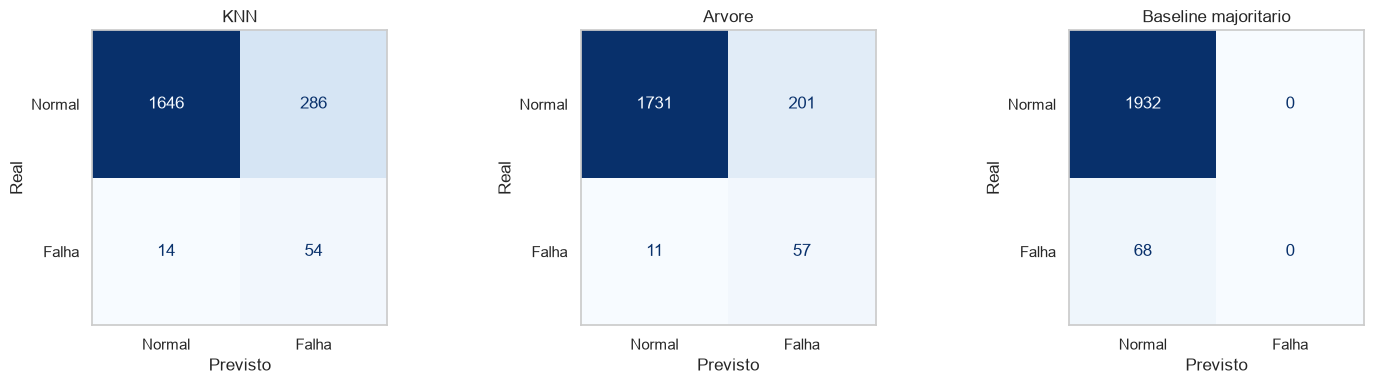

In [14]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_treino_bruto, y_treino)
linhas_metricas = []
matrizes = {}
previsoes_finais = {}
for nome, modelo in {**modelos_finais, 'Baseline majoritario': baseline}.items():
    previsao_treino = modelo.predict(X_treino_bruto)
    previsao_teste = modelo.predict(X_teste_bruto)
    assert len(previsao_teste) == len(y_teste)
    previsoes_finais[nome] = previsao_teste
    matriz = confusion_matrix(y_teste, previsao_teste, labels=[0, 1])
    matrizes[nome] = matriz
    tn, fp, fn, tp = matriz.ravel()
    linhas_metricas.append({
        'modelo': nome,
        'acuracia_treino': accuracy_score(y_treino, previsao_treino),
        'acuracia_teste': accuracy_score(y_teste, previsao_teste),
        'precisao_falha': precision_score(y_teste, previsao_teste, zero_division=0),
        'recall_falha': recall_score(y_teste, previsao_teste, zero_division=0),
        'f1_falha': f1_score(y_teste, previsao_teste, zero_division=0),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    })
metricas_finais = pd.DataFrame(linhas_metricas).set_index('modelo')
display(metricas_finais)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, matriz) in zip(axes, matrizes.items()):
    ConfusionMatrixDisplay(matriz, display_labels=['Normal', 'Falha']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.grid(False)
    ax.set_title(nome)
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')
plt.tight_layout()
plt.show()

### Veredito técnico

**KNN**, com `{'modelo__n_neighbors': 5}`, alcançou F1 médio de validação 0.2716. Na avaliação final, acurácia de treino 0.8417, acurácia de teste 0.8500, precisão da falha 0.1588, recall 0.7941 e F1 0.2647. Houve 14 falsos negativos e 286 falsos positivos no teste.

**Árvore**, com `{'modelo__max_depth': 5}`, alcançou F1 médio de validação 0.3352. Na avaliação final, acurácia de treino 0.8940, acurácia de teste 0.8940, precisão da falha 0.2209, recall 0.8382 e F1 0.3497. Houve 11 falsos negativos e 201 falsos positivos no teste.

O baseline majoritário obteve acurácia 0.9660, recall 0.0000 e F1 0.0000. Sua acurácia elevada acompanha a prevalência de funcionamento normal e oculta a ausência de detecção de falhas.

**Recomenda-se Árvore**, pela maior média de F1 de validação cruzada, critério definido e aplicado antes do acesso às métricas de teste. A maior acurácia final entre os dois modelos selecionados foi observada em Árvore, com 0.8940. Essa comparação atende à rubrica e mantém a escolha de hiperparâmetros já registrada. Os falsos negativos representam falhas que passariam sem alerta, enquanto os falsos positivos gerariam inspeções. Os custos relativos desses erros precisam ser definidos pela operação antes de uma implantação.

**Limitações e melhorias.** O teste contém 68 falhas e a divisão é aleatória. Não foi demonstrada antecedência temporal de horas ou dias. Random Under Sampling reduziu o treino final para 542 registros e descartou grande parte da classe normal. A EDA foi realizada na base completa conforme a rubrica, e as seis configurações foram expostas ao teste para relatório. A decisão foi registrada previamente, mas novas otimizações exigiriam uma avaliação independente. Como continuidade, ampliar os dados, verificar divisões por tempo e equipamento quando existirem metadados apropriados, estimar incerteza das métricas e quantificar custos dos erros. As transformações são reajustadas dentro de cada dobra, incluindo imputação, engenharia, codificação, escala do KNN e balanceamento.

### Validações finais e evidências

Verificamos o teste contra cópias anteriores à modelagem, a seleção das colunas permitidas, a integridade do CSV, a validade das matrizes numéricas e as classes selecionadas pelo sampler. Refazemos o ajuste dos dois pipelines finais com os mesmos parâmetros e sementes para comparar seleções e previsões. Esse ajuste de conferência mantém a configuração já escolhida.

O uso de EDA na base completa segue a rubrica. A seleção é feita com validação interna ao treino, mas as seis configurações são expostas ao teste para o relatório acadêmico. Novas otimizações após essa exposição exigiriam outra avaliação independente. O conjunto não fornece uma avaliação temporal por máquina nem um horizonte de antecedência.

In [15]:
pd.testing.assert_frame_equal(X_teste_bruto, teste_preservado_X)
pd.testing.assert_series_equal(y_teste, teste_preservado_y)
assert hashlib.sha256(CAMINHO_CSV.read_bytes()).hexdigest() == HASH_ORIGINAL
assert json.dumps(escolhas_congeladas, sort_keys=True) == registro_escolhas
contagens_balanceamento = []
for nome, modelo in modelos_finais.items():
    preparacao = modelo.named_steps['preparacao']
    treino_numerico = preparacao.transform(X_treino_bruto)
    teste_numerico = preparacao.transform(X_teste_bruto)
    assert treino_numerico.shape[1] == teste_numerico.shape[1] == 9
    assert np.isfinite(treino_numerico).all() and np.isfinite(teste_numerico).all()
    numericos = preparacao.named_transformers_['numericos']
    assert np.allclose(numericos.named_steps['imputacao'].statistics_,
                       X_treino_bruto[CONTINUAS].median().to_numpy())
    assert ('escala' in numericos.named_steps) == (nome == 'KNN')
    indices = modelo.named_steps['balanceamento'].sample_indices_
    apos = y_treino.iloc[indices].value_counts().sort_index()
    assert apos.loc[0] == apos.loc[1] == y_treino.value_counts().min()
    assert len(np.unique(indices)) == len(indices)
    contagens_balanceamento.append({
        'modelo': nome, 'normais_antes': int((y_treino == 0).sum()),
        'falhas_antes': int((y_treino == 1).sum()),
        'normais_depois': int(apos.loc[0]), 'falhas_depois': int(apos.loc[1]),
    })
    # Categorias novas e nulos usam os transformadores já ajustados.
    amostras_novas = X_teste_bruto.head(3).astype(
        {coluna: 'float64' for coluna in CONTINUAS})
    amostras_novas['tipo'] = amostras_novas['tipo'].astype(object)
    amostras_novas.loc[:, 'tipo'] = 'DESCONHECIDO'
    amostras_novas.loc[:, CONTINUAS] = np.nan
    assert np.isfinite(preparacao.transform(amostras_novas)).all()
    repeticao = clone(pipelines[nome]).set_params(**escolhas_congeladas[nome])
    repeticao.fit(X_treino_bruto, y_treino)
    assert np.array_equal(indices, repeticao.named_steps['balanceamento'].sample_indices_)
    assert np.array_equal(previsoes_finais[nome], repeticao.predict(X_teste_bruto))

pd.testing.assert_frame_equal(X_teste_bruto, teste_preservado_X)
pd.testing.assert_series_equal(y_teste, teste_preservado_y)
assert y_teste.value_counts().sort_index().to_dict() == {0: 1932, 1: 68}
display(pd.DataFrame(contagens_balanceamento))
cpu_final_t4 = processo_t4.cpu_times()
memoria_t4 = processo_t4.memory_info()
evidencias_bloco02 = {
    'python': sys.version.split()[0], 'executavel_kernel': sys.executable,
    'versoes': {nome: metadata.version(nome) for nome in
                ['pandas', 'numpy', 'scikit-learn', 'imbalanced-learn', 'ipykernel', 'nbclient']},
    'escolhas': escolhas_congeladas, 'recomendacao_cv': recomendacao_congelada,
    'f1_cv_finais': f1_cv_finais,
    'comparativo': comparativo_configuracoes.to_dict(orient='records'),
    'resultados_cv': resultados_cv.to_dict(orient='records'),
    'metricas': metricas_finais.reset_index().to_dict(orient='records'),
    'balanceamento': contagens_balanceamento, 'dobras': auditoria_dobras,
    'teste_classes': y_teste.value_counts().sort_index().to_dict(),
    'sha256_csv': HASH_ORIGINAL,
    'tempo_kernel_s': time.perf_counter() - inicio_execucao_t4,
    'cpu_kernel_s': (cpu_final_t4.user + cpu_final_t4.system -
                     cpu_inicio_t4.user - cpu_inicio_t4.system),
    'memoria_rss_mib': memoria_t4.rss / (1024 ** 2),
    'pico_memoria_mib': getattr(memoria_t4, 'peak_wset', memoria_t4.rss) / (1024 ** 2),
    'validacoes': 'Integridade, dobras, imputação, alinhamento, categorias novas, finitude e repetibilidade aprovadas',
}
display(JSON(evidencias_bloco02, expanded=False))
print('Validações do Bloco 02 concluídas.')
limite_threads_t4.restore_original_limits()

,modelo,normais_antes,falhas_antes,normais_depois,falhas_depois
0,KNN,7729,271,271,271
1,Arvore,7729,271,271,271


<IPython.core.display.JSON object>

Validações do Bloco 02 concluídas.
